## Import and Paths

In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt 
s1_path = "../data/raw/s1/Spain_7370579_S1Hand.tif"
s2_path = "../data/raw/s2/Spain_7370579_S2Hand.tif"
mask_path = "../data/raw/masks/Spain_7370579_LabelHand.tif"


## Geospatial Metadata Inspection

In [ ]:
with rasterio.open(s1_path) as s1_src,rasterio.open(s2_path) as s2_src ,  rasterio.open(mask_path) as m_src :
    print("Sentinel 1")
    print(f"Dim : {s1_src.width} : {s1_src.height} ")
    print(f"Bands: {s1_src.count} ")
    print(f"CRS: {s1_src.crs}")
    print(f"Pixel resolution {s2_src.res}\n")

    print("Sentinel 2")
    print(f"Dim : {s2_src.width} : {s2_src.height}")
    print(f"Bands : {s2_src.count}")
    print(f"CRS : {s2_src.crs}")
    print(f"Pixel resolution : {s2_src.res}\n")

    print("Mask")
    print(f"Dim : {m_src.width} : {m_src.height}")
    x




Sentinel 1
Dim : 512 : 512 
Bands: 2 
CRS: EPSG:4326
Pixel resolution (8.983152841195215e-05, 8.983152841195215e-05)

Sentinel 2
Dim : 512 : 512
Bands : 13
CRS : EPSG:4326
Pixel resolution : (8.983152841195215e-05, 8.983152841195215e-05)

Mask
Dim : 512 : 512


## Read bands  and Calculate Water index

In [14]:
with rasterio.open(s2_path) as src:
    green = src.read(3).astype(np.float32)
    nir = src.read(8).astype(np.float32)

    #Calculate the NDWI
    ndwi = np.where(green + nir != 0,(green-nir)/green + nir,0.0)

    rgb = np.stack([src.read(4), src.read(3), src.read(2)], axis=-1).astype(np.float32)
    p2, p98 = np.percentile(rgb, (2, 98))
    rgb_stretched = np.clip((rgb - p2) / (p98 - p2), 0, 1)

with rasterio.open(s1_path) as src:
    sar_vv = src.read(1) 

with rasterio.open(mask_path) as src:
    ground_truth = src.read(1)

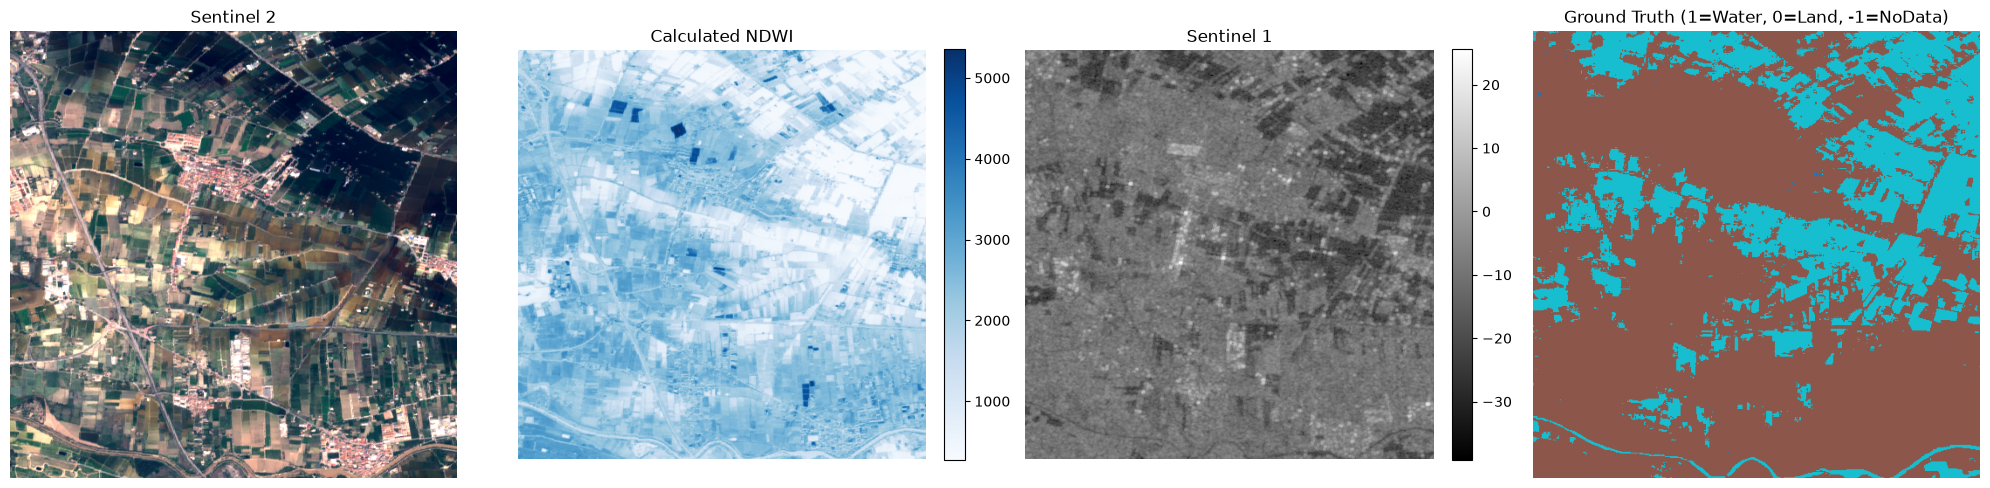

In [ ]:
fig ,axes = plt.subplots(1,4,figsize=(20,5))


#Optical RGB
axes[0].imshow(rgb_stretched)
axes[0].set_title("Sentinel 2")
axes[0].axis("off")

#Calculated NDWI
imagge_ndwi = axes[1].imshow(ndwi,cmap="Blues")
axes[1].set_title("Calculated NDWI")
axes[1].axis("off")
fig.colorbar(imagge_ndwi,ax=axes[1],fraction = 0.046,pad = 0.04)

#Sentinel 1 backscatter
im_sar = axes[2].imshow(sar_vv, cmap="gray")
axes[2].set_title("Sentinel 1")
axes[2].axis("off")
fig.colorbar(im_sar, ax=axes[2], fraction=0.046, pad=0.04)

#Ground trush mask
axes[3].imshow(ground_truth, cmap="tab10")
axes[3].set_title("Ground Truth (1=Water, 0=Land, -1=NoData)")
axes[3].axis("off")

plt.tight_layout()
plt.show()